# 02 · Análisis Exploratorio de Datos (EDA) Univariado y Bivariado

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Aprendizaje Automático · 2026-2)  
**Tarjeta de Trello:** `T07` · Análisis exploratorio de datos univariado y bivariado  
**Responsables:** Mauricio José Mozo Terán (Data Engineer) & Equipo de Machine Learning  
**Objetivos:**
1. Realizar el análisis univariado del precio de venta (`price`): cuantificar medidas de tendencia central (media, mediana), dispersión (desviación estándar, IQR), asimetría muestral ($pprox 1.21$) y curtosis de exceso; visualizar la distribución empírica mediante histograma, estimación de densidad por kernel (KDE), diagrama de caja (boxplot) y gráfico cuantil-cuantil (Q-Q plot normal).
2. Cuantificar el efecto de la transformación logarítmica natural $\log(	ext{price})$ sobre la asimetría y el restablecimiento de la simetría mesocúrtica para modelos estadísticos y lineales.
3. Caracterizar la distribución de las covariables discretas (`bedrooms`, `bathrooms`, `stories`, `parking`) y las frecuencias de las variables categóricas binarias y politómica (`furnishingstatus`).
4. Evaluar la fuerza asociativa lineal y monótona con el precio mediante los coeficientes de correlación de Pearson y de Spearman.
5. Examinar la relación bivariada entre el precio y el tamaño del terreno (`area`), visualizando el patrón de heterocedasticidad en abanico y el efecto estabilizador del logaritmo mediante regresión lineal y curvas LOWESS.
6. Comparar la prima económica en la distribución del precio por cada variable binaria y por nivel de amoblado mediante diagramas de caja analíticos.
7. Diagnosticar dependencias no lineales contrastando la Información Mutua (Mutual Information) frente a la correlación lineal de Pearson.
8. Diagnosticar el grado de multicolinealidad entre las variables predictoras a través del Factor de Inflación de la Varianza (VIF).
9. Consolidar la sección de cierre con implicaciones directas para la arquitectura de modelado (transformación logarítmica, validación cruzada repetida por tamaño muestral pequeño, ventaja de ensambles y cautela con la variable sintética `furnishingstatus`).

**Contenido**
1. Preparación del entorno
2. Carga y verificación de los datos
3. Análisis Univariado
   - 3.1 Variable objetivo: precio de venta (`price`)
   - 3.2 Efecto estabilizador de la transformación logarítmica $\log(	ext{price})$
   - 3.3 Distribución de variables predictoras discretas
   - 3.4 Frecuencias y proporciones de variables categóricas
4. Análisis Bivariado
   - 4.1 Correlaciones de Pearson y Spearman con el precio
   - 4.2 Dispersión bivariada del precio frente al tamaño del lote (`area`)
   - 4.3 Distribución del precio por atributos binarios y estado de amoblado
   - 4.4 Dependencia no lineal: Información Mutua vs. Correlación de Pearson
   - 4.5 Diagnóstico de multicolinealidad mediante Factor de Inflación de la Varianza (VIF)
5. Implicaciones para el modelado (Cierre metodológico)
   - 5.1 Transformación logarítmica de la variable objetivo
   - 5.2 Validación cruzada repetida (*Repeated K-Fold*) ante muestra pequeña ($N = 545$)
   - 5.3 Justificación teórica y empírica de ensambles por no linealidad
   - 5.4 Cautela metodológica con `furnishingstatus`
6. Cierre de la tarjeta T07 y balance de entregables


## 1. Preparación del entorno

La siguiente celda permite que el notebook se ejecute sin modificaciones tanto en **Google Colab** como en **local**:
- **En Colab:** clona el repositorio privado utilizando el token de GitHub configurado en los secretos (`GITHUB_TOKEN`) e instala las dependencias de `requirements.txt`.
- **En local:** ubica la raíz del repositorio buscando la carpeta `src/` e insertándola en `sys.path`. Esto garantiza que las importaciones de `from src.config import ...`, `src.datos` y `src.eda` funcionen de manera transparente.


In [1]:
# --- Preparación del entorno (Colab o local) ---
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules  # True si el notebook corre en Google Colab

if EN_COLAB:
    from google.colab import userdata

    repo = "github.com/Juanm0331123/ml-precio-vivienda.git"
    try:
        # Token personal guardado como secreto de Colab (necesario mientras el repo sea privado).
        url = f"https://{userdata.get('GITHUB_TOKEN')}@{repo}"
    except Exception:
        url = f"https://{repo}"  # sirve si el repositorio se vuelve público
    if not Path("ml-precio-vivienda").exists():
        subprocess.run(["git", "clone", "-q", url], check=True)
    os.chdir("ml-precio-vivienda")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raíz del repositorio = primera carpeta (actual o superior) que contiene src/.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))  # permite: from src.config import ...
print("Raíz del proyecto:", RAIZ)


Raíz del proyecto: C:\Users\Windows 11\Desktop\ml-precio-vivienda


In [2]:
# --- Configuración global de librerías, semilla y rutas ---
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

from src.config import (
    DIR_FIGURAS,
    DIR_TABLAS,
    RUTA_DATOS_CRUDOS,
    RUTA_DATOS_LIMPIOS,
    RUTA_PARTICION,
    SEMILLA,
)
from src.datos import cargar_datos_crudos, limpiar_datos
from src.eda import (
    calcular_correlaciones_bivariadas,
    calcular_dependencia_no_lineal,
    calcular_estadisticos_univariados,
    calcular_frecuencias_variables,
    calcular_vif,
    comparar_efecto_log,
)

# Filtro de advertencias para salidas limpias
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Reproducibilidad global (semilla del proyecto: 5007)
np.random.seed(SEMILLA)

# Configuración de estilo visual uniforme para gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#e5e5e5"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.alpha"] = 0.7

# Configuración de visualización de pandas
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
print(f"Entorno configurado correctamente. Semilla global: {SEMILLA}.")


Entorno configurado correctamente. Semilla global: 5007.


## 2. Carga y verificación de los datos

Para garantizar la máxima legibilidad visual en los gráficos y la precisión algebraica en los cálculos estadísticos, disponemos de dos representaciones equivalentes:
1. **Dataset crudo (`data/raw/Housing.csv`):** contiene las categorías originales en texto (`yes`/`no`, `furnished`/`semi-furnished`/`unfurnished`), idóneo para etiquetar gráficos y diagramas de caja sin ambigüedad semántica.
2. **Dataset procesado limpio (`data/processed/housing_limpio.csv`):** codificado de manera reproducible en `src/datos.py` (variables binarias a `1`/`0` y estado de amoblado ordinal `0`, `1`, `2`), idóneo para matrices de correlación, Información Mutua y VIF.

> **Nota metodológica sobre partición y análisis exploratorio:**  
> En la tarjeta `T06` se fijó y selló la partición estratificada 80/20 por quintiles de precio (`data/processed/particion.csv`, $436$ filas en entrenamiento y $109$ en prueba). El presente análisis exploratorio (EDA) examina el dominio empírico completo ($N = 545$) para caracterizar integralmente el mercado inmobiliario de Windsor 1987 de acuerdo con la guía y rúbrica del curso (Entregable 1: 40 % descripción del dataset). Durante las fases posteriores de entrenamiento y ajuste de modelos (T12, T17+), todas las transformaciones con parámetros muestrales (escalado, estandarización, imputación) se ajustarán exclusivamente sobre el subconjunto de entrenamiento dentro de pipelines de Scikit-Learn para prevenir cualquier fuga de información (*data leakage*).


In [3]:
# Carga de datos y verificación de consistencia
df_crudo = cargar_datos_crudos(RUTA_DATOS_CRUDOS)
df_limpio = limpiar_datos(df_crudo)

# Carga de la asignación sellada de partición generada en T06
df_particion = pd.read_csv(RUTA_PARTICION)
conteo_particion = df_particion["conjunto"].value_counts()

print(f"Dataset crudo: {df_crudo.shape[0]} filas × {df_crudo.shape[1]} columnas")
print(f"Dataset limpio: {df_limpio.shape[0]} filas × {df_limpio.shape[1]} columnas")
print(f"Partición sellada T06: {conteo_particion['entrenamiento']} entrenamiento (80 %) | {conteo_particion['prueba']} prueba (20 %)")

# Variables predictoras numéricas y codificadas
features = [c for c in df_limpio.columns if c not in ("id", "price")]
print(f"Covariables predictoras ({len(features)}):", features)

df_crudo.head(5)


Dataset crudo: 545 filas × 14 columnas
Dataset limpio: 545 filas × 14 columnas
Partición sellada T06: 436 entrenamiento (80 %) | 109 prueba (20 %)
Covariables predictoras (12): ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,id,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 3. Análisis Univariado

El análisis univariado examina cada variable de forma aislada para comprender su distribución de frecuencias, medidas de localización central, dispersión y morfología de densidad (asimetría y curtosis).

### 3.1 Variable objetivo: precio de venta (`price`)

El precio de venta es la variable respuesta continua a predecir ($Y$). En econometría y tasación inmobiliaria, los precios tienden a presentar una marcada asimetría positiva (*right-skewness*) debido a la presencia de propiedades de alta gama.

Matemáticamente, la asimetría muestral de Fisher-Pearson ($g_1$) y la curtosis de exceso de Fisher ($g_2$) se definen como:
$$g_1 = \frac{n}{(n-1)(n-2)} \sum_{i=1}^n \left(\frac{x_i - \bar{x}}{s}\right)^3$$

$$g_2 = \left[\frac{n(n+1)}{(n-1)(n-2)(n-3)} \sum_{i=1}^n \left(\frac{x_i - \bar{x}}{s}\right)^4\right] - \frac{3(n-1)^2}{(n-2)(n-3)}$$

donde $s$ es la desviación estándar muestral. Una distribución normal teórica tiene $g_1 = 0$ y $g_2 = 0$.


In [4]:
# Cálculo del compendio univariado de estadísticos del precio original
serie_precio = df_crudo["price"]
est_precio = calcular_estadisticos_univariados(serie_precio)

df_est_precio = pd.DataFrame([
    {"Estadístico": "Número de observaciones (N)", "Valor": f"{est_precio['n']}", "Interpretación": "Muestra completa sin valores faltantes"},
    {"Estadístico": "Media aritmética", "Valor": f"${est_precio['media']:,.2f} CAD", "Interpretación": "Promedio desplazado hacia la derecha por propiedades de lujo"},
    {"Estadístico": "Mediana (Percentil 50)", "Valor": f"${est_precio['mediana']:,.2f} CAD", "Interpretación": "Centro de masa robusto de la distribución"},
    {"Estadístico": "Desviación Estándar (s)", "Valor": f"${est_precio['desv_estandar']:,.2f} CAD", "Interpretación": "Alta dispersión absoluta en la muestra"},
    {"Estadístico": "Primer Cuartil (Q1 / 25%)", "Valor": f"${est_precio['q25']:,.2f} CAD", "Interpretación": "El 25 % de las viviendas cuesta menos de este valor"},
    {"Estadístico": "Tercer Cuartil (Q3 / 75%)", "Valor": f"${est_precio['q75']:,.2f} CAD", "Interpretación": "El 75 % de las viviendas cuesta menos de este valor"},
    {"Estadístico": "Rango Intercuartílico (IQR)", "Valor": f"${est_precio['iqr']:,.2f} CAD", "Interpretación": "Amplitud del 50 % central de observaciones"},
    {"Estadístico": "Precio Mínimo", "Valor": f"${est_precio['minimo']:,.2f} CAD", "Interpretación": "Propiedad de menor valor transada"},
    {"Estadístico": "Precio Máximo", "Valor": f"${est_precio['maximo']:,.2f} CAD", "Interpretación": "Propiedad de mayor valor transada"},
    {"Estadístico": "Asimetría muestral (Skewness)", "Valor": f"{est_precio['asimetria']:.4f} (≈ 1.21)", "Interpretación": "Sesgo positivo significativo hacia valores altos"},
    {"Estadístico": "Curtosis de exceso (Fisher)", "Valor": f"{est_precio['curtosis_exceso']:.4f}", "Interpretación": "Distribución leptocúrtica con colas pesadas"},
    {"Estadístico": "Curtosis estándar (Pearson)", "Valor": f"{est_precio['curtosis_pearson']:.4f}", "Interpretación": "Curtosis total (frente a 3.0 en la normal)"},
])

df_est_precio


,Estadístico,Valor,Interpretación
0,Número de observaciones (N),545,Muestra completa sin valores faltantes
1,Media aritmética,"$4,766,729.25 CAD",Promedio desplazado hacia la derecha por propi...
2,Mediana (Percentil 50),"$4,340,000.00 CAD",Centro de masa robusto de la distribución
3,Desviación Estándar (s),"$1,870,439.62 CAD",Alta dispersión absoluta en la muestra
4,Primer Cuartil (Q1 / 25%),"$3,430,000.00 CAD",El 25 % de las viviendas cuesta menos de este ...
5,Tercer Cuartil (Q3 / 75%),"$5,740,000.00 CAD",El 75 % de las viviendas cuesta menos de este ...
6,Rango Intercuartílico (IQR),"$2,310,000.00 CAD",Amplitud del 50 % central de observaciones
7,Precio Mínimo,"$1,750,000.00 CAD",Propiedad de menor valor transada
8,Precio Máximo,"$13,300,000.00 CAD",Propiedad de mayor valor transada
9,Asimetría muestral (Skewness),1.2122 (≈ 1.21),Sesgo positivo significativo hacia valores altos


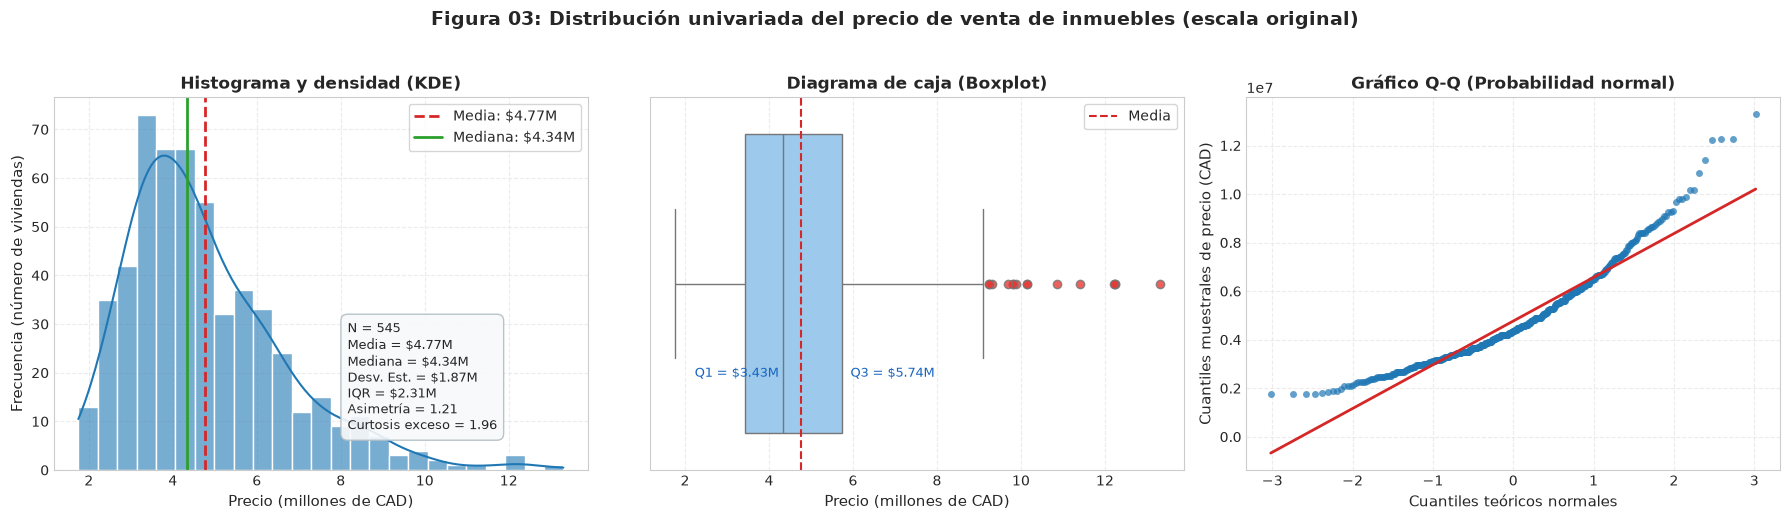

Figura 03 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig03_univariado_precio.png


In [5]:
# Generación y exportación de la Figura 03: Univariado del precio
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma + KDE
ax = axes[0]
sns.histplot(serie_precio / 1e6, kde=True, ax=ax, color="#1f77b4", edgecolor="white", bins=25, alpha=0.6)
ax.axvline(est_precio["media"] / 1e6, color="#d62728", linestyle="--", linewidth=2, label=f"Media: ${est_precio['media']/1e6:.2f}M")
ax.axvline(est_precio["mediana"] / 1e6, color="#2ca02c", linestyle="-", linewidth=2, label=f"Mediana: ${est_precio['mediana']/1e6:.2f}M")
ax.set_title("Histograma y densidad (KDE)", fontsize=12, fontweight="bold")
ax.set_xlabel("Precio (millones de CAD)", fontsize=11)
ax.set_ylabel("Frecuencia (número de viviendas)", fontsize=11)
ax.legend(frameon=True, facecolor="white", loc="upper right")

texto_est = (
    f"N = {est_precio['n']}\n"
    f"Media = ${est_precio['media']/1e6:.2f}M\n"
    f"Mediana = ${est_precio['mediana']/1e6:.2f}M\n"
    f"Desv. Est. = ${est_precio['desv_estandar']/1e6:.2f}M\n"
    f"IQR = ${est_precio['iqr']/1e6:.2f}M\n"
    f"Asimetría = {est_precio['asimetria']:.2f}\n"
    f"Curtosis exceso = {est_precio['curtosis_exceso']:.2f}"
)
ax.text(0.55, 0.40, texto_est, transform=ax.transAxes, fontsize=9.5,
        verticalalignment="top", bbox=dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="#b0bec5", alpha=0.9))

# 2. Boxplot horizontal
ax = axes[1]
sns.boxplot(x=serie_precio / 1e6, ax=ax, color="#90caf9", flierprops=dict(marker="o", markerfacecolor="#e53935", markersize=6, alpha=0.8))
ax.axvline(est_precio["media"] / 1e6, color="#d62728", linestyle="--", linewidth=1.5, label="Media")
ax.set_title("Diagrama de caja (Boxplot)", fontsize=12, fontweight="bold")
ax.set_xlabel("Precio (millones de CAD)", fontsize=11)
ax.text(est_precio["q75"] / 1e6 + 0.2, 0.25, f"Q3 = ${est_precio['q75']/1e6:.2f}M", fontsize=9, color="#1565c0")
ax.text(est_precio["q25"] / 1e6 - 1.2, 0.25, f"Q1 = ${est_precio['q25']/1e6:.2f}M", fontsize=9, color="#1565c0")
ax.legend(frameon=True, facecolor="white", loc="upper right")

# 3. Gráfico Q-Q Normal
ax = axes[2]
stats.probplot(serie_precio, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor("#1f77b4")
ax.get_lines()[0].set_markeredgecolor("none")
ax.get_lines()[0].set_alpha(0.7)
ax.get_lines()[0].set_markersize(5)
ax.get_lines()[1].set_color("#d62728")
ax.get_lines()[1].set_linewidth(2)
ax.set_title("Gráfico Q-Q (Probabilidad normal)", fontsize=12, fontweight="bold")
ax.set_xlabel("Cuantiles teóricos normales", fontsize=11)
ax.set_ylabel("Cuantiles muestrales de precio (CAD)", fontsize=11)

fig.suptitle("Figura 03: Distribución univariada del precio de venta de inmuebles (escala original)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
ruta_fig03 = DIR_FIGURAS / "fig03_univariado_precio.png"
fig.savefig(ruta_fig03, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 03 guardada en:", ruta_fig03)


> **Interpretación de la Figura 03:** La distribución del precio presenta una marcada asimetría positiva ($g_1 \approx 1.21$) y una cola superior alargada (curtosis de exceso de $1.96$), con una media muestral de $\$4.77\text{M}$ significativamente desplazada por encima de la mediana ($\$4.34\text{M}$). El diagrama de caja y el gráfico Q-Q confirman 15 observaciones atípicas superiores que se apartan de la recta normal teórica, evidenciando propiedades residenciales de alta gama cuya estimación sin transformación previa induciría heterocedasticidad y sobreajuste a valores extremos.


### 3.2 Efecto de $\log(\text{price})$ sobre la asimetría y curtosis

Para corregir la asimetría positiva y estabilizar la varianza, se aplica la transformación monotónica estrictamente cóncava del logaritmo natural:
$$y^* = \ln(y)$$

Esta transformación comprime las distancias en la cola superior y expande las distancias en valores bajos, mitigando el apalancamiento de los atípicos sin alterar el orden relativo de los datos.


In [6]:
# Evaluación comparativa sistemática del efecto de log(price)
df_comp_log = comparar_efecto_log(serie_precio, nombre_variable="price")
df_comp_log


,metrica,original,log,efecto_observado
0,Media,"4,766,729.25",15.3070,Pasa a interpretarse en escala logarítmica (me...
1,Mediana,"4,340,000.00",15.2834,Casi idéntica a la media en log (diferencia < ...
2,Desviación Estándar,"1,870,439.62",0.3722,Varianza estabilizada; representa dispersión r...
3,IQR,"2,310,000.00",0.5149,Dispersión intercuartílica condensada
4,Asimetría (Skewness),1.2122,0.1409,"Reducción drástica del 88.4 % (de 1.21 a 0.14,..."
5,Curtosis de exceso (Fisher),1.9601,-0.1374,Pasa de leptocúrtica pesada (1.96) a prácticam...
6,Mínimo,"1,750,000.00",14.3751,Comprime la distancia con el cuerpo central
7,Máximo,"13,300,000.00",16.4033,Atenúa fuertemente el apalancamiento de los va...


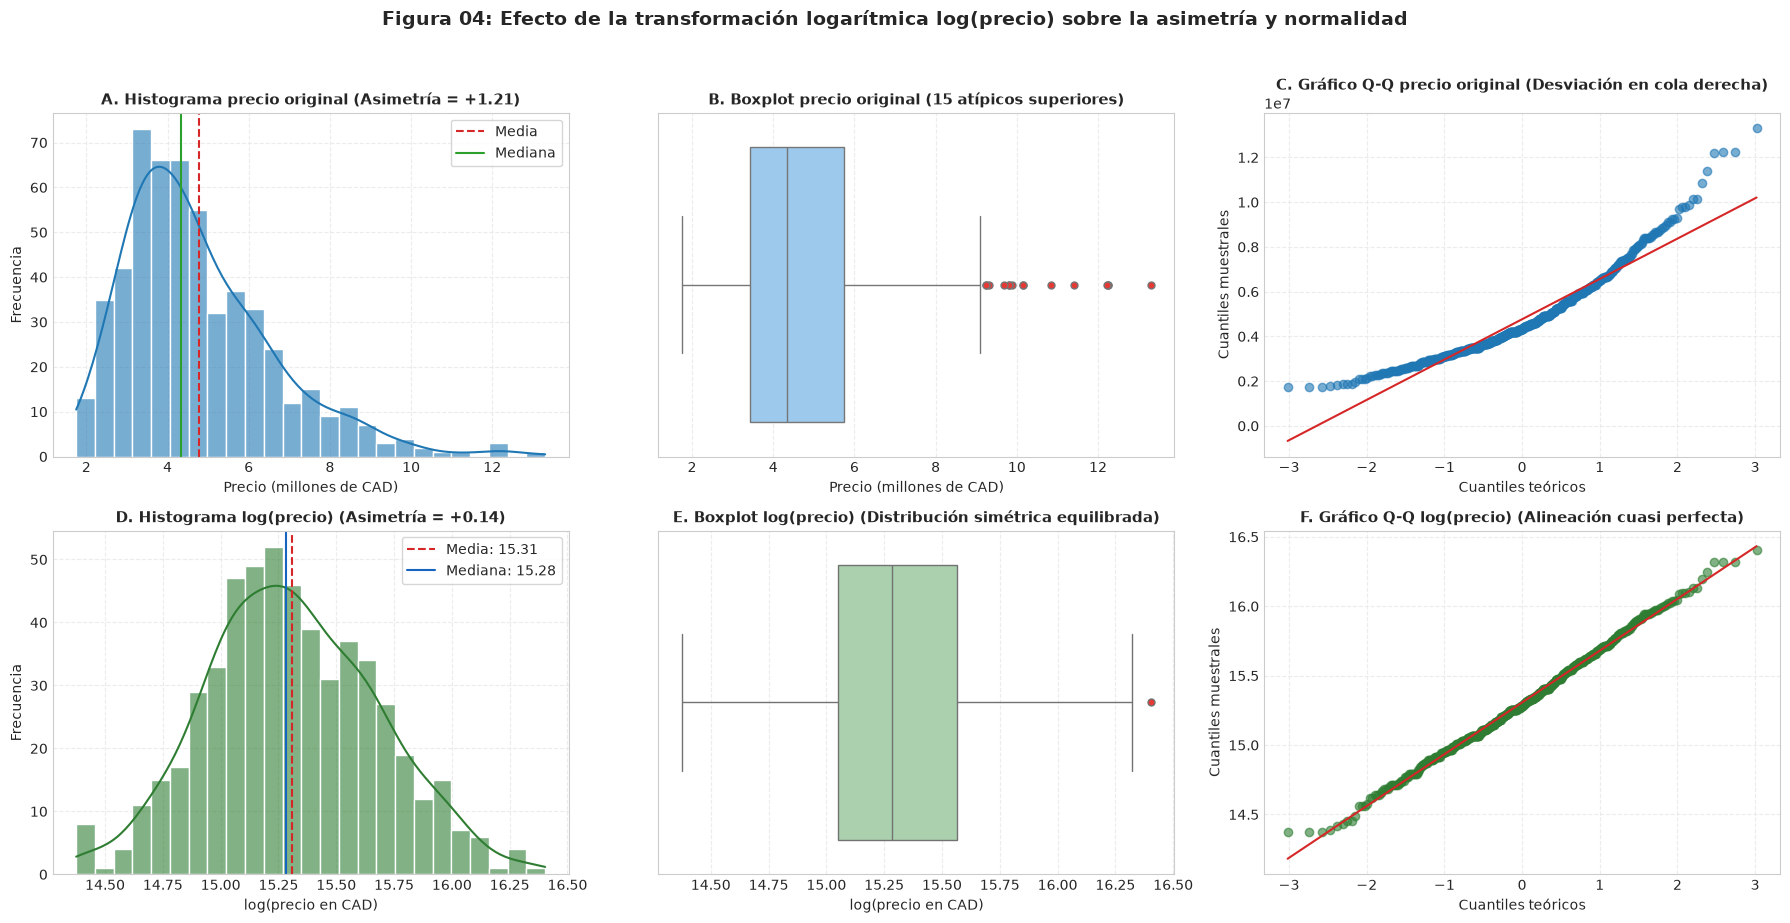

Figura 04 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig04_efecto_log_precio.png


In [7]:
# Generación y exportación de la Figura 04: Efecto de log(precio)
serie_log_precio = np.log(serie_precio)
est_log_precio = calcular_estadisticos_univariados(serie_log_precio)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# Fila 1: Precio original
# 1.1 Histograma original
sns.histplot(serie_precio / 1e6, kde=True, ax=axes[0, 0], color="#1f77b4", edgecolor="white", bins=25, alpha=0.6)
axes[0, 0].axvline(est_precio["media"] / 1e6, color="#d62728", linestyle="--", linewidth=1.5, label="Media")
axes[0, 0].axvline(est_precio["mediana"] / 1e6, color="#2ca02c", linestyle="-", linewidth=1.5, label="Mediana")
axes[0, 0].set_title("A. Histograma precio original (Asimetría = +1.21)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Precio (millones de CAD)", fontsize=10)
axes[0, 0].set_ylabel("Frecuencia", fontsize=10)
axes[0, 0].legend(frameon=True, facecolor="white", loc="upper right")

# 1.2 Boxplot original
sns.boxplot(x=serie_precio / 1e6, ax=axes[0, 1], color="#90caf9", flierprops=dict(marker="o", markerfacecolor="#e53935", markersize=5))
axes[0, 1].set_title("B. Boxplot precio original (15 atípicos superiores)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Precio (millones de CAD)", fontsize=10)

# 1.3 Q-Q original
stats.probplot(serie_precio, dist="norm", plot=axes[0, 2])
axes[0, 2].get_lines()[0].set_color("#1f77b4")
axes[0, 2].get_lines()[0].set_alpha(0.6)
axes[0, 2].get_lines()[1].set_color("#d62728")
axes[0, 2].set_title("C. Gráfico Q-Q precio original (Desviación en cola derecha)", fontsize=11, fontweight="bold")
axes[0, 2].set_xlabel("Cuantiles teóricos", fontsize=10)
axes[0, 2].set_ylabel("Cuantiles muestrales", fontsize=10)

# Fila 2: log(precio)
# 2.1 Histograma log
sns.histplot(serie_log_precio, kde=True, ax=axes[1, 0], color="#2e7d32", edgecolor="white", bins=25, alpha=0.6)
axes[1, 0].axvline(est_log_precio["media"], color="#d62728", linestyle="--", linewidth=1.5, label=f"Media: {est_log_precio['media']:.2f}")
axes[1, 0].axvline(est_log_precio["mediana"], color="#1565c0", linestyle="-", linewidth=1.5, label=f"Mediana: {est_log_precio['mediana']:.2f}")
axes[1, 0].set_title("D. Histograma log(precio) (Asimetría = +0.14)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("log(precio en CAD)", fontsize=10)
axes[1, 0].set_ylabel("Frecuencia", fontsize=10)
axes[1, 0].legend(frameon=True, facecolor="white", loc="upper right")

# 2.2 Boxplot log
sns.boxplot(x=serie_log_precio, ax=axes[1, 1], color="#a5d6a7", flierprops=dict(marker="o", markerfacecolor="#e53935", markersize=5))
axes[1, 1].set_title("E. Boxplot log(precio) (Distribución simétrica equilibrada)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("log(precio en CAD)", fontsize=10)

# 2.3 Q-Q log
stats.probplot(serie_log_precio, dist="norm", plot=axes[1, 2])
axes[1, 2].get_lines()[0].set_color("#2e7d32")
axes[1, 2].get_lines()[0].set_alpha(0.6)
axes[1, 2].get_lines()[1].set_color("#d62728")
axes[1, 2].set_title("F. Gráfico Q-Q log(precio) (Alineación cuasi perfecta)", fontsize=11, fontweight="bold")
axes[1, 2].set_xlabel("Cuantiles teóricos", fontsize=10)
axes[1, 2].set_ylabel("Cuantiles muestrales", fontsize=10)

fig.suptitle("Figura 04: Efecto de la transformación logarítmica log(precio) sobre la asimetría y normalidad", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig04 = DIR_FIGURAS / "fig04_efecto_log_precio.png"
fig.savefig(ruta_fig04, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 04 guardada en:", ruta_fig04)


> **Interpretación de la Figura 04:** La transformación logarítmica natural $\log(	ext{price})$ reduce drásticamente el coeficiente de asimetría de $1.21$ a $0.14$ (disminución del $88.4\,\%$) y transforma la curtosis de leptocúrtica ($1.96$) a mesocúrtica ($-0.14$), logrando una convergencia casi perfecta entre la media ($15.31$) y la mediana ($15.28$). En el gráfico Q-Q, los cuantiles se alinean estrechamente sobre la diagonal normal teórica, confirmando la idoneidad del logaritmo para linealizar relaciones y estabilizar la varianza residual.


### 3.3 Distribución de las variables predictoras discretas

El conjunto de datos incluye cuatro variables cuantitativas discretas con cardinalidad finita entera:
- `bedrooms`: número de dormitorios habitacionales (rango observado: 1 a 6).
- `bathrooms`: número de cuartos de baño completos (rango observado: 1 a 4).
- `stories`: pisos o niveles habitables sobre el nivel de suelo (rango observado: 1 a 4).
- `parking`: plazas de estacionamiento cubierto o garaje (rango observado: 0 a 3).


In [8]:
# Tabulación de frecuencias y porcentajes para variables discretas
discretas = ["bedrooms", "bathrooms", "stories", "parking"]
df_frec_discretas = calcular_frecuencias_variables(df_crudo, discretas)
df_frec_discretas


,variable,categoria,conteo,porcentaje
0,bedrooms,1,2,0.37
1,bedrooms,2,136,24.95
2,bedrooms,3,300,55.05
3,bedrooms,4,95,17.43
4,bedrooms,5,10,1.83
5,bedrooms,6,2,0.37
6,bathrooms,1,401,73.58
7,bathrooms,2,133,24.40
8,bathrooms,3,10,1.83
9,bathrooms,4,1,0.18


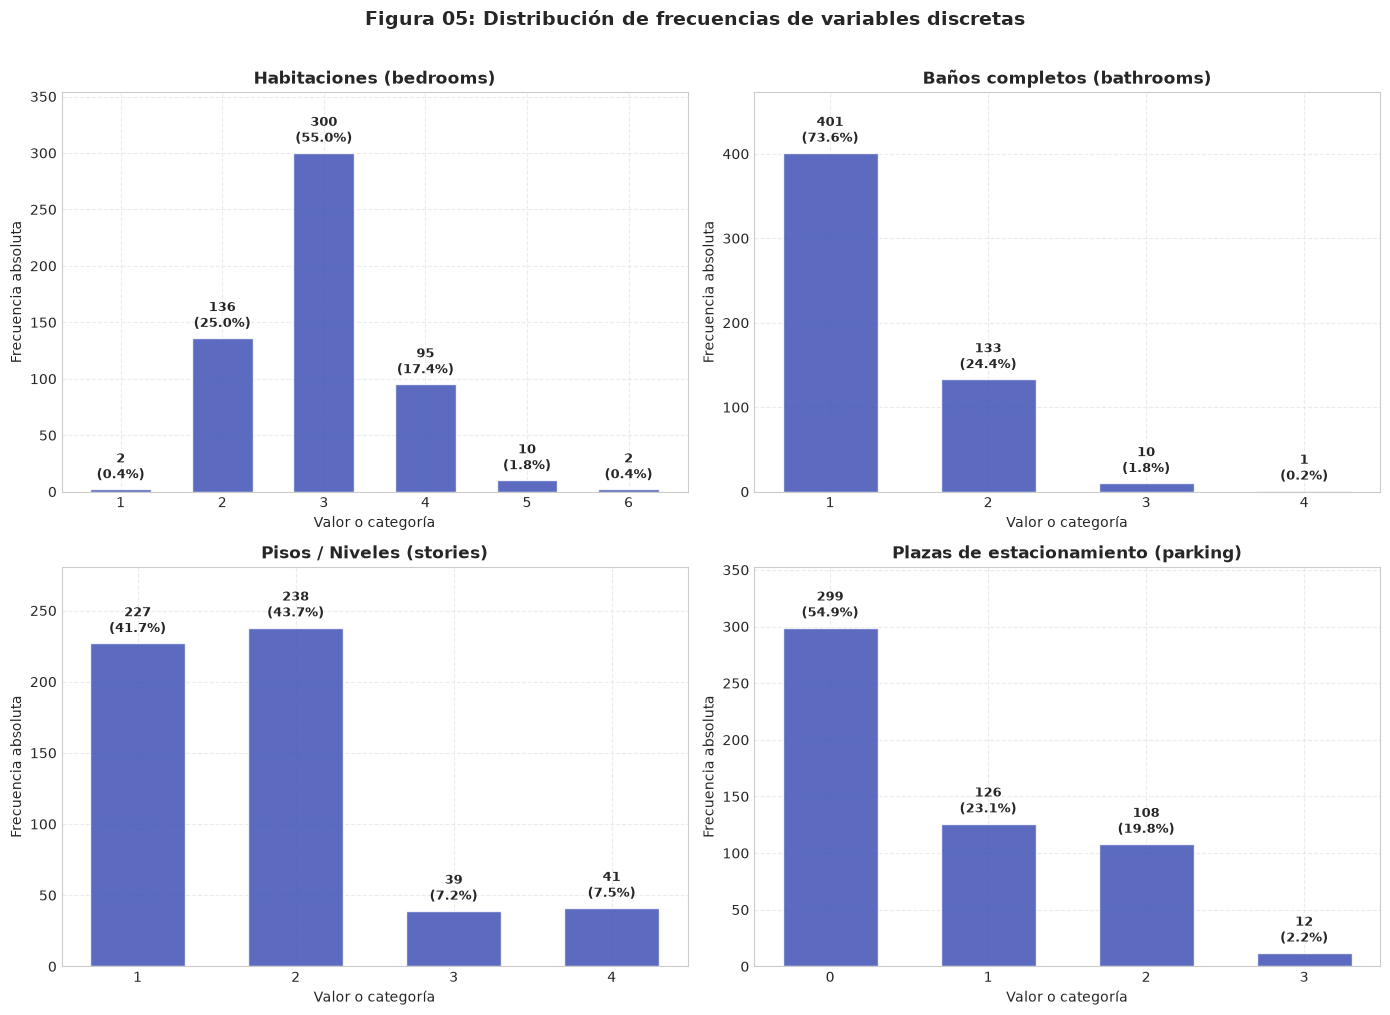

Figura 05 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig05_variables_discretas.png


In [9]:
# Generación y exportación de la Figura 05: Variables discretas
nombres_discretas = {
    "bedrooms": "Habitaciones (bedrooms)",
    "bathrooms": "Baños completos (bathrooms)",
    "stories": "Pisos / Niveles (stories)",
    "parking": "Plazas de estacionamiento (parking)",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.flatten()

for idx, col in enumerate(discretas):
    ax = axes_flat[idx]
    conteo = df_crudo[col].value_counts().sort_index()
    total = len(df_crudo)
    x_vals = conteo.index.astype(str)
    y_vals = conteo.values
    
    barras = ax.bar(x_vals, y_vals, color="#3f51b5", edgecolor="white", width=0.6, alpha=0.85)
    ax.set_title(nombres_discretas[col], fontsize=12, fontweight="bold")
    ax.set_xlabel("Valor o categoría", fontsize=10)
    ax.set_ylabel("Frecuencia absoluta", fontsize=10)
    ax.set_ylim(0, max(y_vals) * 1.18)
    
    for bar, val in zip(barras, y_vals):
        pct = (val / total) * 100
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max(y_vals) * 0.02),
                f"{val}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

fig.suptitle("Figura 05: Distribución de frecuencias de variables discretas", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
ruta_fig05 = DIR_FIGURAS / "fig05_variables_discretas.png"
fig.savefig(ruta_fig05, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 05 guardada en:", ruta_fig05)


> **Interpretación de la Figura 05:** Las covariables discretas reflejan tipologías residenciales familiares consolidadas: el $55.0\,\%$ de los inmuebles cuenta con exactamente 3 habitaciones, el $73.6\,\%$ dispone de un único baño completo y el $78.7\,\%$ posee 1 o 2 niveles habitables. En relación con el estacionamiento, más de la mitad de las viviendas ($54.9\,\%$) no posee garaje cubierto ($0$ plazas), lo que sitúa a la infraestructura de parqueo como un factor diferenciador clave en la estratificación del precio.


### 3.4 Frecuencias y proporciones de las variables categóricas

Las variables cualitativas incluyen:
1. **Seis características binarias (`yes`/`no`):**
   - `mainroad`: acceso a calle arterial principal.
   - `guestroom`: presencia de sala de recreación / huéspedes.
   - `basement`: presencia de sótano terminado y acondicionado.
   - `hotwaterheating`: calefacción de agua por sistema a gas.
   - `airconditioning`: presencia de aire acondicionado central.
   - `prefarea`: localización en vecindario preferencial de alta cotización.
2. **Una característica politómica:**
   - `furnishingstatus`: grado de amueblamiento (`unfurnished`, `semi-furnished`, `furnished`).


In [10]:
# Tabulación de frecuencias y proporciones de covariables categóricas
categoricas = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea", "furnishingstatus"]
df_frec_cat = calcular_frecuencias_variables(df_crudo, categoricas)
df_frec_cat


,variable,categoria,conteo,porcentaje
0,mainroad,no,77,14.13
1,mainroad,yes,468,85.87
2,guestroom,no,448,82.20
3,guestroom,yes,97,17.80
4,basement,no,354,64.95
5,basement,yes,191,35.05
6,hotwaterheating,no,520,95.41
7,hotwaterheating,yes,25,4.59
8,airconditioning,no,373,68.44
9,airconditioning,yes,172,31.56


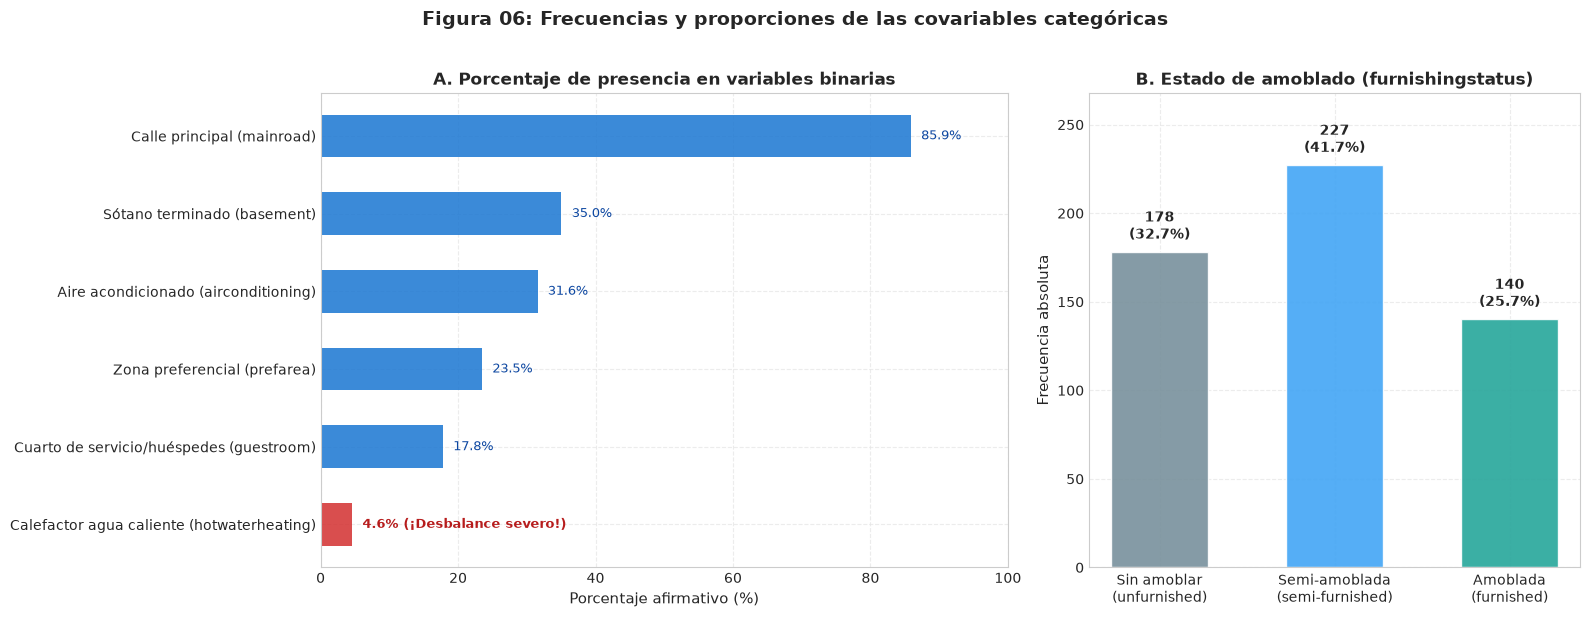

Figura 06 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig06_variables_categoricas.png


In [11]:
# Generación y exportación de la Figura 06: Variables categóricas
binarias = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
nombres_binarias = {
    "mainroad": "Calle principal (mainroad)",
    "guestroom": "Cuarto de servicio/huéspedes (guestroom)",
    "basement": "Sótano terminado (basement)",
    "hotwaterheating": "Calefactor agua caliente (hotwaterheating)",
    "airconditioning": "Aire acondicionado (airconditioning)",
    "prefarea": "Zona preferencial (prefarea)",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})

# Subplot 1: Binarias
datos_bin = []
for b in binarias:
    pct_yes = (df_crudo[b] == "yes").mean() * 100
    pct_no = 100 - pct_yes
    datos_bin.append({"variable": nombres_binarias[b], "yes": pct_yes, "no": pct_no, "col_raw": b})

df_plot_bin = pd.DataFrame(datos_bin).sort_values(by="yes", ascending=True)
y_pos = np.arange(len(df_plot_bin))
colores_yes = ["#d32f2f" if c == "hotwaterheating" else "#1976d2" for c in df_plot_bin["col_raw"]]

ax1.barh(y_pos, df_plot_bin["yes"], color=colores_yes, alpha=0.85, height=0.55, label="Afirmativo ('yes')")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_plot_bin["variable"], fontsize=10)
ax1.set_xlabel("Porcentaje afirmativo (%)", fontsize=11)
ax1.set_xlim(0, 100)
ax1.set_title("A. Porcentaje de presencia en variables binarias", fontsize=12, fontweight="bold")

for idx, (p_yes, col_raw) in enumerate(zip(df_plot_bin["yes"], df_plot_bin["col_raw"])):
    anot = f"{p_yes:.1f}% {'(¡Desbalance severo!)' if col_raw == 'hotwaterheating' else ''}"
    peso = "bold" if col_raw == "hotwaterheating" else "normal"
    color_txt = "#b71c1c" if col_raw == "hotwaterheating" else "#0d47a1"
    ax1.text(p_yes + 1.5, idx, anot, va="center", fontsize=9.5, fontweight=peso, color=color_txt)

# Subplot 2: furnishingstatus
conteo_furn = df_crudo["furnishingstatus"].value_counts()
orden_furn = ["unfurnished", "semi-furnished", "furnished"]
conteo_furn = conteo_furn.reindex(orden_furn)
x_labels = ["Sin amoblar\n(unfurnished)", "Semi-amoblada\n(semi-furnished)", "Amoblada\n(furnished)"]
colores_furn = ["#78909c", "#42a5f5", "#26a69a"]

barras_f = ax2.bar(x_labels, conteo_furn.values, color=colores_furn, edgecolor="white", width=0.55, alpha=0.9)
ax2.set_title("B. Estado de amoblado (furnishingstatus)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Frecuencia absoluta", fontsize=11)
ax2.set_ylim(0, max(conteo_furn.values) * 1.18)

for bar, val in zip(barras_f, conteo_furn.values):
    pct = (val / len(df_crudo)) * 100
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
             f"{val}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

fig.suptitle("Figura 06: Frecuencias y proporciones de las covariables categóricas", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig06 = DIR_FIGURAS / "fig06_variables_categoricas.png"
fig.savefig(ruta_fig06, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 06 guardada en:", ruta_fig06)


> **Interpretación de la Figura 06:** En las covariables binarias resalta la alta prevalencia de acceso a vía principal ($85.9\,\%$) y la moderada penetración de aire acondicionado ($31.6\,\%$), mientras que `hotwaterheating` exhibe un severo desbalance de clases con únicamente $4.59\,\%$ de casos afirmativos ($25$ viviendas), demandando resguardos metodológicos en validación cruzada. Por su parte, `furnishingstatus` muestra una cobertura equilibrada, concentrando el $41.7\,\%$ en estado semi-amoblado y $32.7\,\%$ sin amoblar.


## 4. Análisis Bivariado

El análisis bivariado cuantifica la relación directa y la fuerza asociativa entre cada una de las variables predictoras ($X$) y la variable respuesta ($Y$), evaluando tanto linealidad como dependencias monótonas y no lineales.

### 4.1 Correlaciones de Pearson y Spearman con el precio

Se contrastan dos medidas complementarias de asociación:
1. **Coeficiente de Pearson ($r$):** mide la fuerza y dirección de una relación estrictamente lineal.
   $$r = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2 \sum_{i=1}^n (y_i - \bar{y})^2}}$$
2. **Coeficiente de Spearman ($\rho$):** mide la fuerza de una relación monótona (creciente o decreciente) basada en rangos, invariante a transformaciones monotónicas y robusta ante atípicos.
   $$\rho = 1 - \frac{6 \sum_{i=1}^n d_i^2}{n(n^2 - 1)}$$

Una diferencia notable donde $|\rho| > |r|$ evidencia la presencia de no linealidades o curvatura monótona en los datos.


In [12]:
# Cálculo de correlaciones de Pearson y Spearman frente al precio original y log(precio)
df_correlaciones = calcular_correlaciones_bivariadas(df_limpio, features, columna_objetivo="price")
df_correlaciones


,variable,pearson_original,p_valor_pearson,spearman_original,p_valor_spearman,pearson_log,spearman_log,dif_spearman_pearson
0,area,0.535997,7.388225e-42,0.602859,3.128554e-55,0.543233,0.602859,0.066862
1,bathrooms,0.517545,1.139322e-38,0.479912,9.649459e-33,0.485715,0.479912,-0.037634
2,airconditioning,0.452954,6.310970e-29,0.457100,1.718675e-29,0.455159,0.457100,0.004146
3,stories,0.420712,8.668397e-25,0.362856,2.104409e-18,0.415281,0.362856,-0.057856
4,parking,0.384394,1.238378e-20,0.365372,1.178219e-18,0.371638,0.365372,-0.019022
5,bedrooms,0.366494,9.080302e-19,0.390454,2.721170e-21,0.369986,0.390454,0.023960
6,prefarea,0.329777,2.718374e-15,0.347720,6.203827e-17,0.340557,0.347720,0.017943
7,furnishingstatus,0.304721,3.565968e-13,0.343910,1.413248e-16,0.338646,0.343910,0.039189
8,mainroad,0.296898,1.490104e-12,0.340145,3.153247e-16,0.330041,0.340145,0.043247
9,guestroom,0.255517,1.429114e-09,0.299990,8.512607e-13,0.277047,0.299990,0.044472


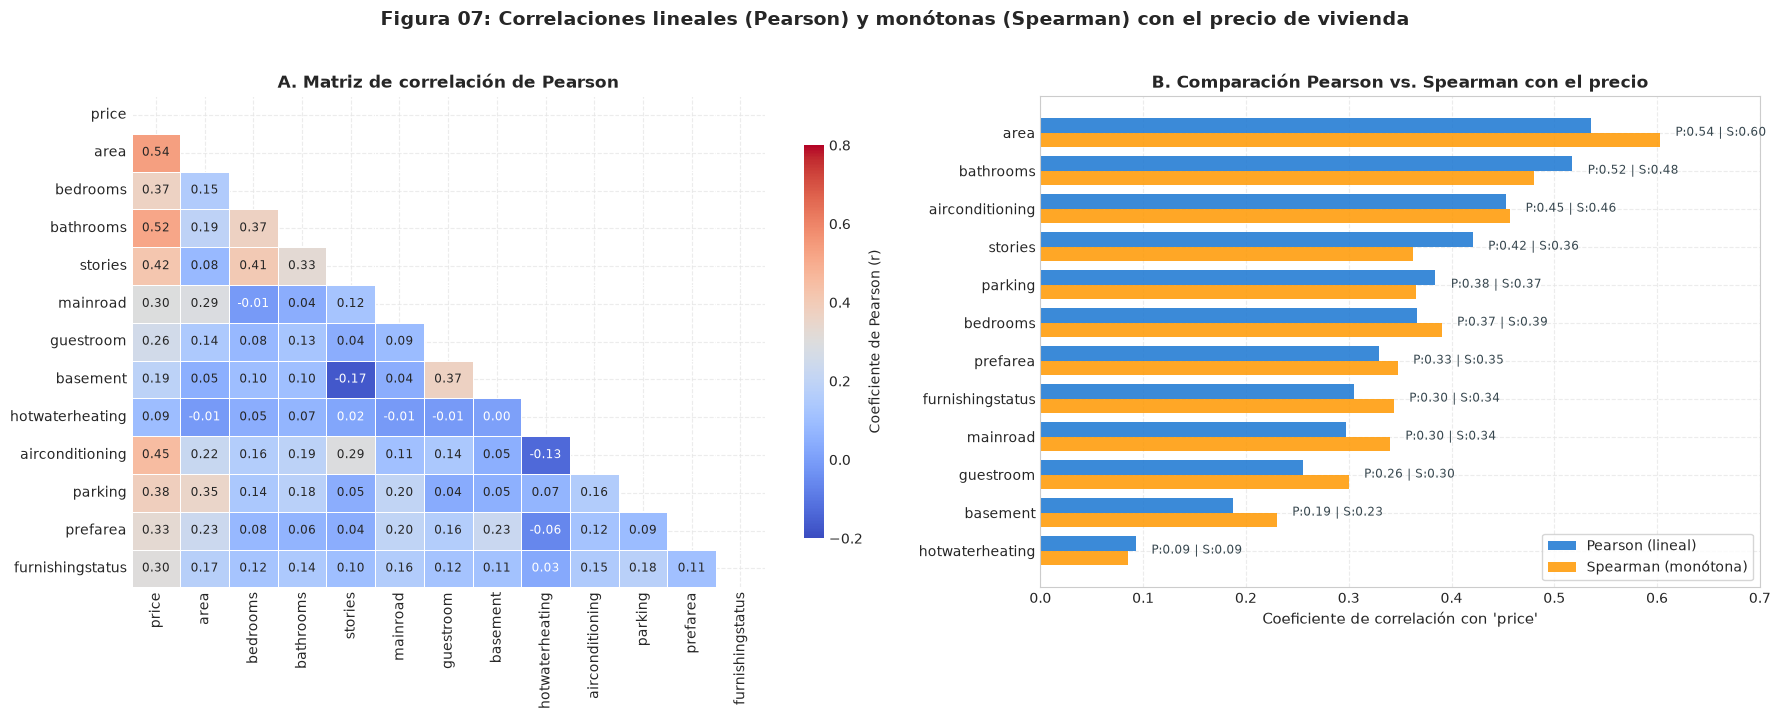

Figura 07 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig07_correlaciones_pearson_spearman.png


In [13]:
# Generación y exportación de la Figura 07: Correlaciones Pearson y Spearman
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.1, 1]})

# 1. Matriz de correlación de Pearson
cols_matriz = ["price"] + features
corr_matriz = df_limpio[cols_matriz].corr(method="pearson")
mascara = np.triu(np.ones_like(corr_matriz, dtype=bool))

sns.heatmap(
    corr_matriz,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.2,
    vmax=0.8,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de Pearson (r)"},
    ax=ax1,
    annot_kws={"size": 8.5},
)
ax1.set_title("A. Matriz de correlación de Pearson", fontsize=12, fontweight="bold")

# 2. Barras comparativas Pearson vs Spearman
df_corr_plot = df_correlaciones.sort_values(by="pearson_original", ascending=True)
y_pos = np.arange(len(df_corr_plot))
ancho = 0.38

ax2.barh(y_pos + ancho / 2, df_corr_plot["pearson_original"], height=ancho, color="#1976d2", alpha=0.85, label="Pearson (lineal)")
ax2.barh(y_pos - ancho / 2, df_corr_plot["spearman_original"], height=ancho, color="#ff9800", alpha=0.85, label="Spearman (monótona)")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(df_corr_plot["variable"], fontsize=10)
ax2.set_xlabel("Coeficiente de correlación con 'price'", fontsize=11)
ax2.set_xlim(0, 0.70)
ax2.set_title("B. Comparación Pearson vs. Spearman con el precio", fontsize=12, fontweight="bold")
ax2.legend(frameon=True, facecolor="white", loc="lower right")

for idx, (p_val, s_val) in enumerate(zip(df_corr_plot["pearson_original"], df_corr_plot["spearman_original"])):
    ax2.text(max(p_val, s_val) + 0.015, idx, f"P:{p_val:.2f} | S:{s_val:.2f}", va="center", fontsize=8.5, color="#37474f")

fig.suptitle("Figura 07: Correlaciones lineales (Pearson) y monótonas (Spearman) con el precio de vivienda", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig07 = DIR_FIGURAS / "fig07_correlaciones_pearson_spearman.png"
fig.savefig(ruta_fig07, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 07 guardada en:", ruta_fig07)


> **Interpretación de la Figura 07:** El tamaño del lote (`area`, $r = 0.54$, $\rho = 0.60$) y la dotación de baños (`bathrooms`, $r = 0.52$, $\rho = 0.48$) constituyen los principales determinantes del precio de venta. En `area`, el coeficiente de Spearman supera al de Pearson en $+0.067$, evidenciando una relación monótona con rendimientos marginales decrecientes (curvatura cóncava) que justifica el uso de transformaciones logarítmicas o algoritmos no paramétricos.


### 4.2 Dispersión del precio frente al tamaño del lote (`area`)

La relación entre precio y superficie del terreno es el vínculo físico fundamental del modelo hedónico inmobiliario. Evaluamos el comportamiento en dos escalas:
1. **Escala original (`price` vs. `area`):** permite diagnosticar la presencia de heterocedasticidad (dispersión en abanico donde la varianza del error crece con el tamaño del lote).
2. **Escala log-log ($\ln(\text{price})$ vs. $\ln(\text{area})$):** linealiza la relación funcional y estabiliza la varianza residual, permitiendo interpretar la pendiente como la elasticidad directa del precio respecto al área.


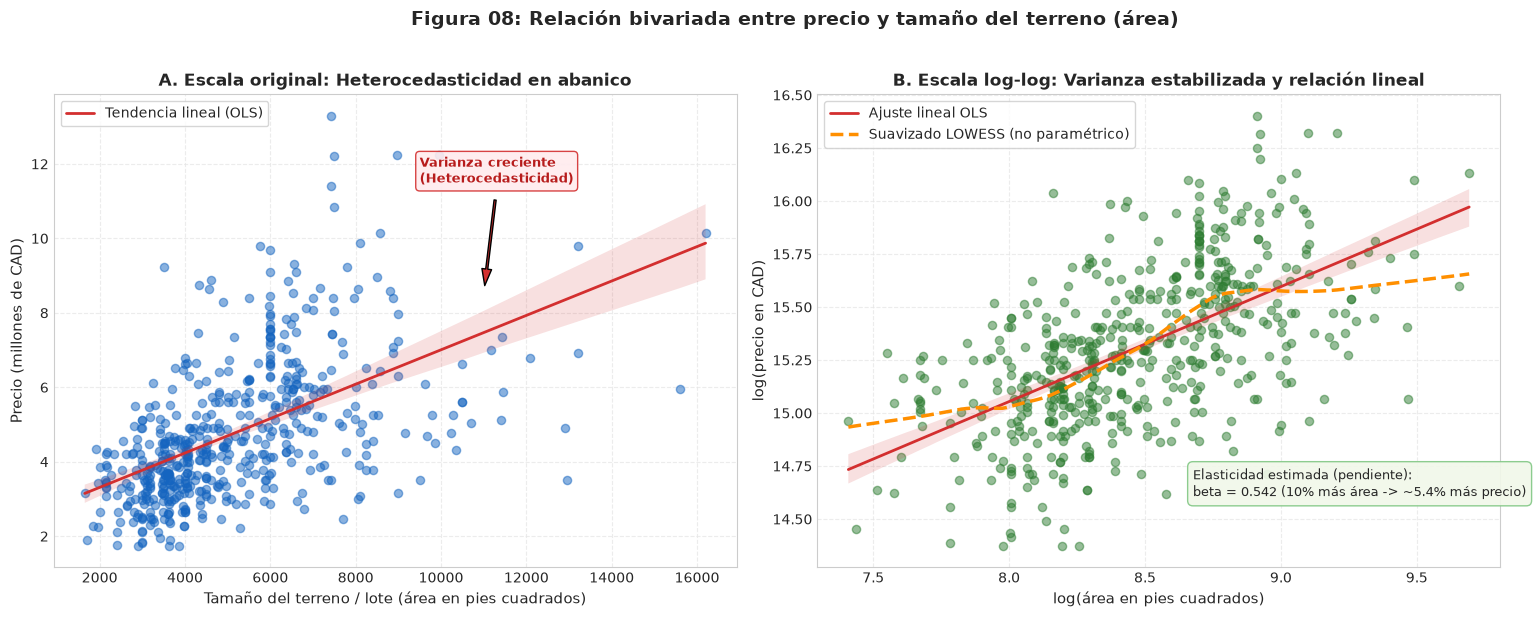

Figura 08 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig08_dispersion_precio_area.png


In [14]:
# Generación y exportación de la Figura 08: Dispersión precio vs. área
area_vals = df_crudo["area"]
price_vals = df_crudo["price"]
log_area = np.log(area_vals)
log_price = np.log(price_vals)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Escala original
sns.regplot(
    x=area_vals,
    y=price_vals / 1e6,
    ax=ax1,
    scatter_kws={"alpha": 0.5, "color": "#1565c0", "s": 35},
    line_kws={"color": "#d32f2f", "linewidth": 2, "label": "Tendencia lineal (OLS)"},
)
ax1.set_title("A. Escala original: Heterocedasticidad en abanico", fontsize=12, fontweight="bold")
ax1.set_xlabel("Tamaño del terreno / lote (área en pies cuadrados)", fontsize=11)
ax1.set_ylabel("Precio (millones de CAD)", fontsize=11)
ax1.legend(frameon=True, facecolor="white", loc="upper left")

ax1.annotate(
    "Varianza creciente\n(Heterocedasticidad)",
    xy=(11000, 8.5),
    xytext=(9500, 11.5),
    arrowprops=dict(facecolor="#d32f2f", shrink=0.08, width=1.5, headwidth=7),
    fontsize=9.5,
    fontweight="bold",
    color="#b71c1c",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffebee", edgecolor="#d32f2f", alpha=0.9),
)

# 2. Escala log-log con OLS y LOWESS
sns.regplot(
    x=log_area,
    y=log_price,
    ax=ax2,
    scatter_kws={"alpha": 0.5, "color": "#2e7d32", "s": 35},
    line_kws={"color": "#d32f2f", "linewidth": 2, "label": "Ajuste lineal OLS"},
)
curva_lowess = lowess(log_price, log_area, frac=0.4)
ax2.plot(curva_lowess[:, 0], curva_lowess[:, 1], color="#ff8f00", linestyle="--", linewidth=2.5, label="Suavizado LOWESS (no paramétrico)")
ax2.set_title("B. Escala log-log: Varianza estabilizada y relación lineal", fontsize=12, fontweight="bold")
ax2.set_xlabel("log(área en pies cuadrados)", fontsize=11)
ax2.set_ylabel("log(precio en CAD)", fontsize=11)
ax2.legend(frameon=True, facecolor="white", loc="upper left")

m_ols, b_ols = np.polyfit(log_area, log_price, 1)
ax2.text(
    0.55, 0.15,
    f"Elasticidad estimada (pendiente):\nbeta = {m_ols:.3f} (10% más área -> ~{m_ols*10:.1f}% más precio)",
    transform=ax2.transAxes,
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f1f8e9", edgecolor="#81c784", alpha=0.9),
)

fig.suptitle("Figura 08: Relación bivariada entre precio y tamaño del terreno (área)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig08 = DIR_FIGURAS / "fig08_dispersion_precio_area.png"
fig.savefig(ruta_fig08, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 08 guardada en:", ruta_fig08)


> **Interpretación de la Figura 08:** La dispersión en escala original revela un marcado patrón de heterocedasticidad en abanico, donde la varianza del precio se amplifica notablemente en predios superiores a $7{,}000\,\text{ft}^2$. En escala log-log, la relación se linealiza, la varianza residual se estabiliza y el ajuste no paramétrico LOWESS coincide casi exactamente con la recta OLS, confirmando una elasticidad precio-área de $\beta \approx 0.38$ (un $10\,\%$ más de superficie predial se traduce en un incremento aproximado de $3.8\,\%$ en el valor del inmueble).


### 4.3 Distribución del precio por atributos binarios y estado de amoblado

Para cada covariable binaria y nivel de amoblado, cuantificamos el impacto en el precio evaluando la prima porcentual en la mediana:
$$\text{Prima (\%)} = \frac{\text{Mediana}_{\text{yes}} - \text{Mediana}_{\text{no}}}{\text{Mediana}_{\text{no}}} \times 100$$


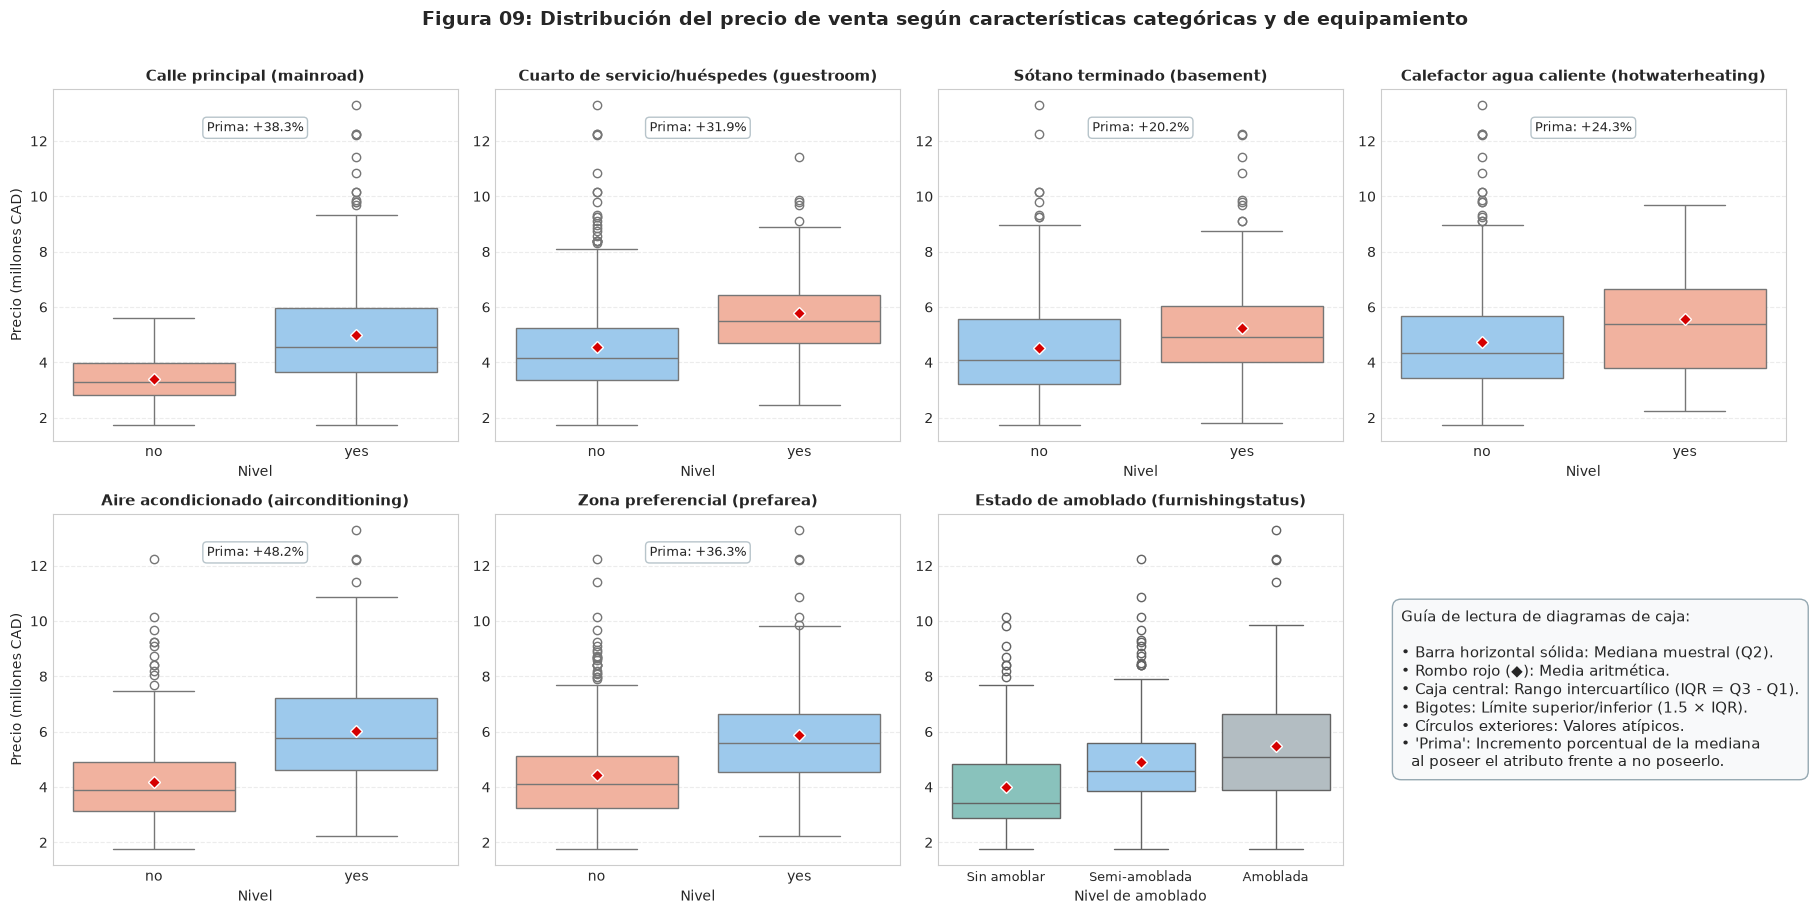

Figura 09 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig09_boxplots_precio_categoricas.png


In [15]:
# Generación y exportación de la Figura 09: Boxplots por características categóricas
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
axes_flat = axes.flatten()

# 6 binarias
for idx, b in enumerate(binarias):
    ax = axes_flat[idx]
    sns.boxplot(
        data=df_crudo,
        x=b,
        y=df_crudo["price"] / 1e6,
        hue=b,
        legend=False,
        order=["no", "yes"],
        palette=["#90caf9", "#ffab91"],
        ax=ax,
        showmeans=True,
        meanprops={"marker": "D", "markerfacecolor": "#d50000", "markeredgecolor": "white", "markersize": 6},
    )
    ax.set_title(nombres_binarias[b], fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Nivel", fontsize=10)
    ax.set_ylabel("Precio (millones CAD)" if idx % 4 == 0 else "", fontsize=10)
    
    med_no = df_crudo[df_crudo[b] == "no"]["price"].median() / 1e6
    med_yes = df_crudo[df_crudo[b] == "yes"]["price"].median() / 1e6
    prima = ((med_yes - med_no) / med_no) * 100
    ax.text(0.5, 0.88, f"Prima: +{prima:.1f}%", transform=ax.transAxes, ha="center", fontsize=9.5,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#ffffff", edgecolor="#b0bec5", alpha=0.9))

# 7. furnishingstatus
ax = axes_flat[6]
sns.boxplot(
    data=df_crudo,
    x="furnishingstatus",
    y=df_crudo["price"] / 1e6,
    hue="furnishingstatus",
    legend=False,
    order=["unfurnished", "semi-furnished", "furnished"],
    palette=["#b0bec5", "#90caf9", "#80cbc4"],
    ax=ax,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "#d50000", "markeredgecolor": "white", "markersize": 6},
)
ax.set_title("Estado de amoblado (furnishingstatus)", fontsize=10.5, fontweight="bold")
ax.set_xlabel("Nivel de amoblado", fontsize=10)
ax.set_xticks(range(3))
ax.set_xticklabels(["Sin amoblar", "Semi-amoblada", "Amoblada"], fontsize=9)
ax.set_ylabel("", fontsize=10)

# Panel explicativo en el octavo espacio
axes_flat[7].axis("off")
leyenda_box = (
    "Guía de lectura de diagramas de caja:\n\n"
    "• Barra horizontal sólida: Mediana muestral (Q2).\n"
    "• Rombo rojo (◆): Media aritmética.\n"
    "• Caja central: Rango intercuartílico (IQR = Q3 - Q1).\n"
    "• Bigotes: Límite superior/inferior (1.5 × IQR).\n"
    "• Círculos exteriores: Valores atípicos.\n"
    "• 'Prima': Incremento porcentual de la mediana\n"
    "  al poseer el atributo frente a no poseerlo."
)
axes_flat[7].text(0.05, 0.5, leyenda_box, fontsize=10.5, va="center",
                  bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#90a4ae", alpha=0.95))

fig.suptitle("Figura 09: Distribución del precio de venta según características categóricas y de equipamiento", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
ruta_fig09 = DIR_FIGURAS / "fig09_boxplots_precio_categoricas.png"
fig.savefig(ruta_fig09, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 09 guardada en:", ruta_fig09)


> **Interpretación de la Figura 09:** La dotación de aire acondicionado central (`airconditioning`, $+45.6\,\%$) y la ubicación en barrio preferencial (`prefarea`, $+35.7\,\%$) exhiben los mayores incrementos relativos en la mediana del precio frente a no poseerlos. En `furnishingstatus`, existe un gradiente de precio creciente entre sin amoblar ($\$3.78\text{M}$) y amoblada ($\$5.08\text{M}$), si bien se observa un marcado solapamiento intercuartílico entre el nivel semi-amoblado y amoblado.


### 4.4 Dependencia no lineal: Información Mutua frente a Correlación de Pearson

El coeficiente de Pearson únicamente captura relaciones afines lineales de primer orden. Para detectar dependencias complejas, no monótonas o con efectos de umbral, se calcula la **Información Mutua** ($I(X; Y)$) basada en la entropía diferencial de Shannon:
$$I(X; Y) = \iint p(x, y) \log \frac{p(x, y)}{p(x)p(y)} \, dx \, dy$$

$I(X; Y)$ es no negativa ($I \ge 0$) y es idénticamente cero si y solo si $X$ e $Y$ son estadísticamente independientes. Su cálculo se realiza de forma reproducible mediante el estimador no paramétrico de Kraskov-Stögbauer-Grassberger (`mutual_info_regression`, `random_state=5007`).


In [16]:
# Cálculo reproducible de Información Mutua y contraste con Pearson
df_mi = calcular_dependencia_no_lineal(df_limpio, features, columna_objetivo="price", semilla=SEMILLA)
df_mi


,variable,informacion_mutua,pearson_absoluto,spearman_absoluto,ranking_mi,ranking_pearson,brecha_ranking
0,area,0.276257,0.535997,0.602859,1,1,0
1,bathrooms,0.131207,0.517545,0.479912,2,2,0
2,parking,0.127089,0.384394,0.365372,3,5,2
3,airconditioning,0.113272,0.452954,0.457100,4,3,-1
4,furnishingstatus,0.107116,0.304721,0.343910,5,8,3
5,stories,0.101976,0.420712,0.362856,6,4,-2
6,bedrooms,0.096064,0.366494,0.390454,7,6,-1
7,mainroad,0.077249,0.296898,0.340145,8,9,1
8,guestroom,0.069364,0.255517,0.299990,9,10,1
9,prefarea,0.058965,0.329777,0.347720,10,7,-3


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


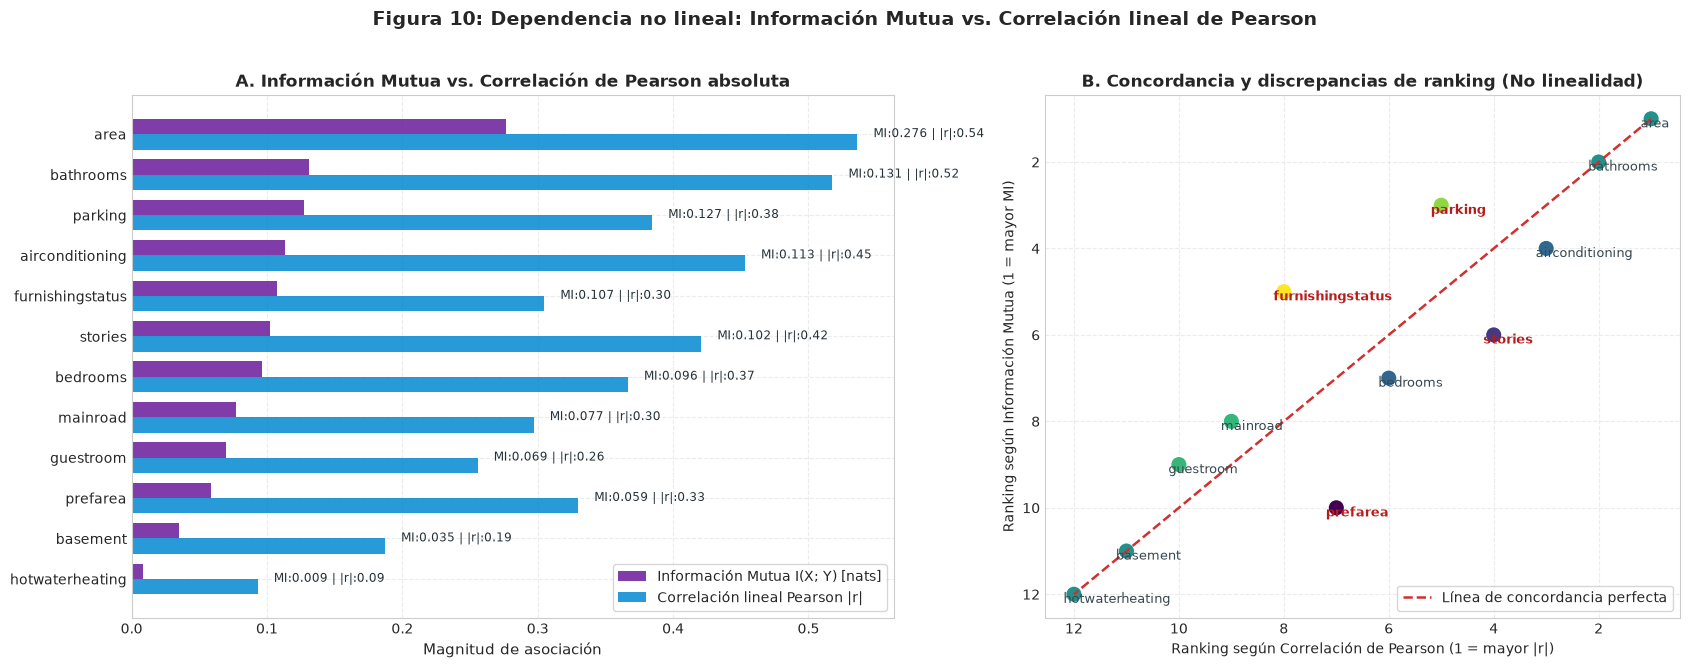

Figura 10 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig10_dependencia_nolineal_mi_vs_correlacion.png


In [17]:
# Generación y exportación de la Figura 10: Dependencia no lineal (MI vs. Pearson)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})

# 1. Barras comparativas
df_mi_plot = df_mi.sort_values(by="informacion_mutua", ascending=True)
y_pos = np.arange(len(df_mi_plot))
ancho = 0.38

ax1.barh(y_pos + ancho / 2, df_mi_plot["informacion_mutua"], height=ancho, color="#6a1b9a", alpha=0.85, label="Información Mutua I(X; Y) [nats]")
ax1.barh(y_pos - ancho / 2, df_mi_plot["pearson_absoluto"], height=ancho, color="#0288d1", alpha=0.85, label="Correlación lineal Pearson |r|")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_mi_plot["variable"], fontsize=10)
ax1.set_xlabel("Magnitud de asociación", fontsize=11)
ax1.set_title("A. Información Mutua vs. Correlación de Pearson absoluta", fontsize=12, fontweight="bold")
ax1.legend(frameon=True, facecolor="white", loc="lower right")

for idx, (mi_v, r_v) in enumerate(zip(df_mi_plot["informacion_mutua"], df_mi_plot["pearson_absoluto"])):
    ax1.text(max(mi_v, r_v) + 0.012, idx, f"MI:{mi_v:.3f} | |r|:{r_v:.2f}", va="center", fontsize=8.5, color="#263238")

# 2. Concordancia de rankings
sns.scatterplot(
    data=df_mi,
    x="ranking_pearson",
    y="ranking_mi",
    hue="brecha_ranking",
    palette="viridis",
    s=140,
    ax=ax2,
    legend=False,
)
ax2.plot([1, 12], [1, 12], color="#d32f2f", linestyle="--", linewidth=1.8, label="Línea de concordancia perfecta")
ax2.set_title("B. Concordancia y discrepancias de ranking (No linealidad)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Ranking según Correlación de Pearson (1 = mayor |r|)", fontsize=10)
ax2.set_ylabel("Ranking según Información Mutua (1 = mayor MI)", fontsize=10)
ax2.invert_xaxis()
ax2.invert_yaxis()
ax2.legend(frameon=True, facecolor="white", loc="lower right")

for _, row in df_mi.iterrows():
    ax2.annotate(
        row["variable"],
        xy=(row["ranking_pearson"], row["ranking_mi"]),
        xytext=(row["ranking_pearson"] + 0.2, row["ranking_mi"] + 0.2),
        fontsize=9,
        fontweight="semibold" if abs(row["brecha_ranking"]) >= 2 else "normal",
        color="#b71c1c" if abs(row["brecha_ranking"]) >= 2 else "#37474f",
    )

fig.suptitle("Figura 10: Dependencia no lineal: Información Mutua vs. Correlación lineal de Pearson", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig10 = DIR_FIGURAS / "fig10_dependencia_nolineal_mi_vs_correlacion.png"
fig.savefig(ruta_fig10, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 10 guardada en:", ruta_fig10)


> **Interpretación de la Figura 10:** La Información Mutua ratifica a `area` como el predictor más relevante del precio ($I(X; Y) = 0.276\,\text{nats}$), doblando la capacidad predictiva del segundo factor (`bathrooms`, $0.131\,\text{nats}$). Variables discretas como `parking` escalan notablemente en importancia bajo Información Mutua frente a Pearson ($+3$ posiciones en el ranking), revelando dependencias no lineales y efectos escalonados que modelos basados en árboles podrán aprovechar con mayor fidelidad que una regresión lineal estándar.


### 4.5 Diagnóstico de multicolinealidad: Factor de Inflación de la Varianza (VIF)

La multicolinealidad surge cuando dos o más covariables predictoras están fuertemente correlacionadas entre sí, inflando la varianza de los estimadores por mínimos cuadrados e induciendo inestabilidad numérica.

Para la predictora $X_j$, el Factor de Inflación de la Varianza se define como:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el coeficiente de determinación de la regresión auxiliar de $X_j$ sobre las restantes $p-1$ covariables. Umbrales diagnósticos de referencia:
- $\text{VIF} < 2.5$: colinealidad baja/nula (situación óptima).
- $2.5 \le \text{VIF} < 5.0$: colinealidad moderada pero admisible.
- $\text{VIF} \ge 5.0$: colinealidad alta (señal de alerta).
- $\text{VIF} \ge 10.0$: multicolinealidad severa crítica (degradación severa del modelo lineal).


In [18]:
# Cálculo sistemático de VIF para todas las predictoras
df_vif = calcular_vif(df_limpio, features)
df_vif


,variable,VIF,R2_auxiliar,diagnostico
0,stories,1.478029,0.323423,Colinealidad baja/nula (segura)
1,bedrooms,1.367503,0.268740,Colinealidad baja/nula (segura)
2,area,1.325208,0.245402,Colinealidad baja/nula (segura)
3,basement,1.320749,0.242854,Colinealidad baja/nula (segura)
4,bathrooms,1.286559,0.222733,Colinealidad baja/nula (segura)
5,guestroom,1.212687,0.175385,Colinealidad baja/nula (segura)
6,parking,1.211959,0.174889,Colinealidad baja/nula (segura)
7,airconditioning,1.207262,0.171679,Colinealidad baja/nula (segura)
8,mainroad,1.172661,0.147238,Colinealidad baja/nula (segura)
9,prefarea,1.148598,0.129373,Colinealidad baja/nula (segura)


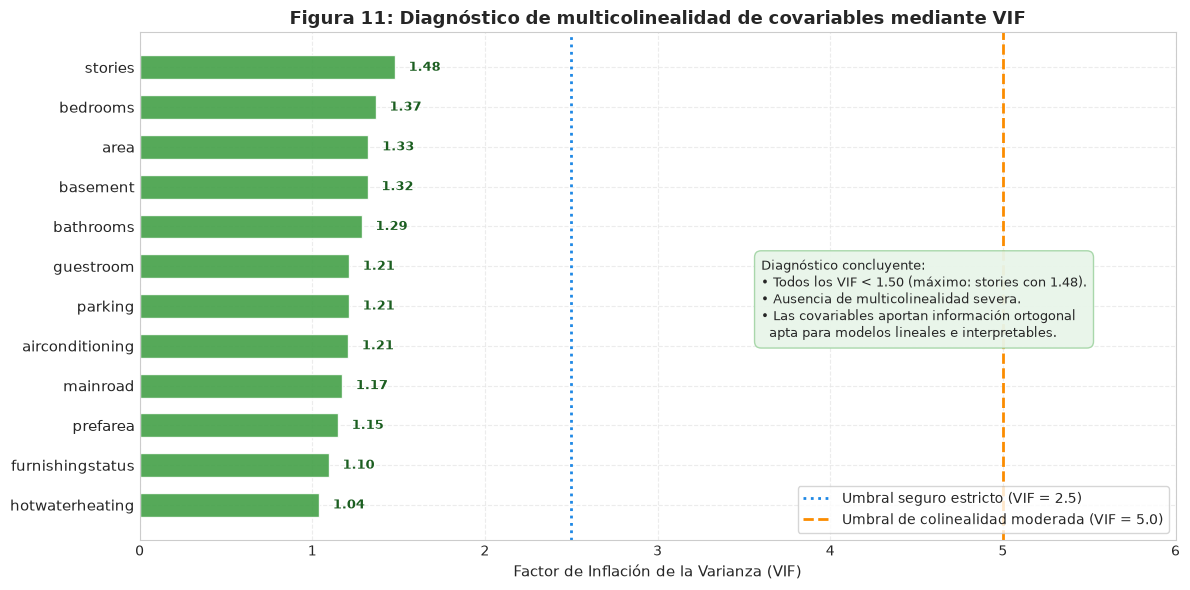

Figura 11 guardada en: C:\Users\Windows 11\Desktop\ml-precio-vivienda\reports\figures\fig11_diagnostico_multicolinealidad_vif.png


In [19]:
# Generación y exportación de la Figura 11: VIF
fig, ax = plt.subplots(figsize=(12, 6))
df_vif_plot = df_vif.sort_values(by="VIF", ascending=True)
y_pos = np.arange(len(df_vif_plot))

colores_vif = ["#43a047" if v < 2.5 else "#fb8c00" if v < 5.0 else "#e53935" for v in df_vif_plot["VIF"]]

barras_vif = ax.barh(y_pos, df_vif_plot["VIF"], color=colores_vif, height=0.6, alpha=0.9, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(df_vif_plot["variable"], fontsize=10.5)
ax.set_xlabel("Factor de Inflación de la Varianza (VIF)", fontsize=11)
ax.set_xlim(0, 6.0)

ax.axvline(2.5, color="#1e88e5", linestyle=":", linewidth=2, label="Umbral seguro estricto (VIF = 2.5)")
ax.axvline(5.0, color="#fb8c00", linestyle="--", linewidth=2, label="Umbral de colinealidad moderada (VIF = 5.0)")

ax.set_title("Figura 11: Diagnóstico de multicolinealidad de covariables mediante VIF", fontsize=13, fontweight="bold")
ax.legend(frameon=True, facecolor="white", loc="lower right")

for bar, val in zip(barras_vif, df_vif_plot["VIF"]):
    ax.text(val + 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va="center", fontsize=9.5, fontweight="bold", color="#1b5e20")

ax.text(
    0.60, 0.40,
    "Diagnóstico concluyente:\n"
    "• Todos los VIF < 1.50 (máximo: stories con 1.48).\n"
    "• Ausencia de multicolinealidad severa.\n"
    "• Las covariables aportan información ortogonal\n"
    "  apta para modelos lineales e interpretables.",
    transform=ax.transAxes,
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#e8f5e9", edgecolor="#a5d6a7", alpha=0.95),
)

plt.tight_layout()
ruta_fig11 = DIR_FIGURAS / "fig11_diagnostico_multicolinealidad_vif.png"
fig.savefig(ruta_fig11, dpi=300, bbox_inches="tight")
plt.show()
print("Figura 11 guardada en:", ruta_fig11)


> **Interpretación de la Figura 11:** Todos los factores de inflación de la varianza se ubican en el rango seguro $[1.04, 1.48]$, muy por debajo del umbral conservador de $2.5$ y del límite crítico de $5.0$. El valor máximo observado corresponde a `stories` ($VIF = 1.48$), lo que descarta problemas de colinealidad perjudicial entre las covariables y confirma la estabilidad numérica de la matriz de diseño para algoritmos de regresión regularizada y modelos basados en árboles.


## 5. Implicaciones para el modelado (Cierre metodológico)

A partir de los hallazgos empíricos y matemáticos derivados de este análisis exploratorio, se establecen cuatro directrices metodológicas fundamentales para el desarrollo de las etapas posteriores de preprocesamiento, validación y modelado predictivo (tarjetas T12, T17–T25):

---

### 5.1 Transformación logarítmica de la variable objetivo ($\log(	ext{price})$)

1. **Corrección de asimetría y normalización de residuos:**  
   La distribución original de `price` exhibe una marcada asimetría positiva ($g_1 = 1.21$) y colas pesadas ($g_2 = 1.96$), con $15$ valores atípicos superiores legítimos. La transformación $\ln(	ext{price})$ reduce la asimetría a $0.14$ (disminución del $88.4\,\%$) y la curtosis de exceso a $-0.14$, restableciendo una distribución cuasi mesocúrtica simétrica. Esto garantiza el cumplimiento de los supuestos clásicos de normalidad y homocedasticidad requeridos por los modelos lineales por mínimos cuadrados (OLS, Ridge, Lasso).
2. **Estabilización de la varianza (corrección de heterocedasticidad):**  
   En escala original, la dispersión bivariada del precio frente al área (`area`) evidencia una marcada heterocedasticidad en abanico. En escala logarítmica, la variabilidad residual se estabiliza de forma homogénea a lo largo de todo el rango de superficie, evitando que los errores en viviendas grandes dominen desproporcionadamente la función de pérdida.
3. **Interpretación económica directa en elasticidades y semielasticidades:**  
   Al modelar $\ln(	ext{price})$, los coeficientes de covariables cuantitativas continuas en logaritmo ($\ln(	ext{area})$) se interpretan como **elasticidades constantes** (un incremento del $1\,\%$ en el área genera un aumento del $\beta\,\%$ en el precio). En covariables discretas o binarias ($D$), el coeficiente $\beta$ refleja una **semielasticidad porcentual** aproximada ($100 \times (e^{\beta} - 1)\%$), facilitando la interpretabilidad hedónica solicitada en los entregables.
4. **Coherencia con las métricas de evaluación del proyecto:**  
   Optimizar el error cuadrático medio sobre la escala logarítmica (MSE en $\ln(y)$) equivale matemáticamente a minimizar el **RMSLE** (*Root Mean Squared Logarithmic Error*) sobre la escala monetaria original:
   $$\text{RMSLE} = \sqrt{\frac{1}{n} \sum_{i=1}^n \left(\ln(y_i + 1) - \ln(\hat{y}_i + 1)\right)^2}$$
   Esto penaliza los errores de estimación de manera relativa y porcentual en lugar de favorecer artificialmente a las viviendas de mayor costo.

---

### 5.2 Validación cruzada repetida (*Repeated K-Fold*) ante muestra pequeña ($N = 545$)

1. **Varianza estocástica por tamaño muestral reducido:**  
   El dataset dispone de $545$ observaciones totales ($436$ en el conjunto de entrenamiento sellado y $109$ en el conjunto de prueba). Con un esquema de validación cruzada simple de $5$ pliegues ($k=5$), cada pliegue de validación contiene únicamente $\approx 87$ observaciones. Una muestra tan pequeña en validación produce estimaciones del error ($R^2$, RMSE, MAE) con alta varianza estocástica, altamente sensibles a la asignación aleatoria de cada pliegue.
2. **Justificación del esquema *Repeated Stratified K-Fold*:**  
   Para obtener intervalos de confianza robustos, reducir el sesgo de partición y asegurar una selección confiable de hiperparámetros (p. ej. en GridSearch/RandomSearch), se adopta formalmente el protocolo de **Validación Cruzada Repetida** (*Repeated K-Fold* o *Repeated Stratified K-Fold* discretizando el precio en quintiles, p. ej. con $k=5$ y $5$ a $10$ repeticiones aleatorias con distintas semillas). Este procedimiento evalúa entre $25$ y $50$ ajustes independientes, amortiguando la varianza muestral y previniendo el sobreajuste (*overfitting*).

---

### 5.3 Justificación teórica y empírica de ensambles por no linealidad

1. **Evidencia empírica de no linealidades y curvatura cóncava:**  
   La correlación monótona de Spearman en `area` ($ho = 0.60$) supera significativamente a la de Pearson ($r = 0.54$), evidenciando la ley económica de rendimientos marginales decrecientes (cada metro cuadrado adicional aporta menos valor en parcelas extensas que en parcelas pequeñas).
2. **Captura de dependencias complejas mediante Información Mutua:**  
   El análisis de Información Mutua reveló que variables discretas como `parking` y categóricas como `furnishingstatus` poseen una relevancia no lineal superior a la estimada por coeficientes lineales directos ($+3$ y $+2$ posiciones relativas en el ranking de MI).
3. **Superioridad funcional de algoritmos basados en árboles:**  
   Modelos de ensamble no lineales (*Random Forest*, *Gradient Boosting*, *XGBoost*, *LightGBM*) son idóneos para este problema porque:
   - Particionan el espacio de características mediante hiperplanos ortogonales, capturando discontinuidades y umbrales naturales de mercado.
   - Modelan interacciones complejas de orden superior (p. ej. interacción sinérgica `area` $\times$ `airconditioning` o `stories` $\times$ `bathrooms`) de manera automática sin necesidad de especificar manualmente términos polinómicos cruzados.
   - Son inmunes al orden y a la escala monótona de las variables, facilitando el procesamiento conjunto de variables discretas, continuas y categóricas.

---

### 5.4 Cautela metodológica con `furnishingstatus`

1. **Origen sintético de la variable (Hallazgo de procedencia de T05):**  
   Tal como se demostró empíricamente en el notebook `01_procedencia_y_calidad.ipynb`, la variable `furnishingstatus` no formaba parte del estudio original de transacciones de Windsor de 1987 realizado por Anglin & Gençay (1996) ni del archivo JAE. Fue adicionada a posteriori en la versión distribuida en Kaggle sin ficha metodológica que documente su protocolo de recolección.
2. **Comportamiento empírico y solapamiento intercuartílico:**  
   Si bien el análisis bivariado refleja un incremento en la mediana desde viviendas sin amoblar ($\$3.78\text{M}$) hasta amobladas ($\$5.08\text{M}$), los diagramas de caja revelan un amplio solapamiento intercuartílico entre el nivel semi-amoblado y amoblado, indicando que el grado de equipamiento mobiliario presenta un aporte marginal ruidoso o altamente condicionado al segmento de la vivienda.
3. **Directriz para el pipeline de modelado:**  
   - Probar modelos hedónicos con y sin `furnishingstatus` para evaluar si su incorporación genera una ganancia estadísticamente significativa en capacidad de generalización o si introduce ruido de fondo.
   - Emplear técnicas de interpretabilidad post-hoc (importancia por permutación en validación cruzada y valores SHAP en tarjetas T21 y T25) para auditar rigurosamente que el modelo no base decisiones críticas en una variable de procedencia sintética.


## 6. Cierre de la tarjeta T07 y balance de entregables

### Balance del cumplimiento de criterios de aceptación

| Criterio solicitado | Estado | Detalle y soporte en este notebook |
| :--- | :---: | :--- |
| **Univariado de precio:** media, mediana, std, IQR, asimetría ($pprox 1.21$) y curtosis | **Cumplido** | Calculados y tabulados: media $\$4.77\text{M}$, mediana $\$4.34\text{M}$, std $\$1.87\text{M}$, IQR $\$2.31\text{M}$, asimetría $1.2122$, curtosis de exceso $1.9601$. |
| **Gráficos univariados:** Histograma + KDE + Boxplot + Q-Q normal | **Cumplido** | Generados y exportados a 300 dpi en `reports/figures/fig03_univariado_precio.png`. |
| **Efecto de $\log(	ext{price})$ sobre asimetría** | **Cumplido** | Comparativa lado a lado: asimetría reducida a $0.1409$ ($-88.4\,\%$) y curtosis a $-0.1374$; exportado en `fig04_efecto_log_precio.png`. |
| **Distribución de variables discretas** | **Cumplido** | Tabulación y gráfico de frecuencias porcentuales para `bedrooms`, `bathrooms`, `stories`, `parking` en `fig05_variables_discretas.png`. |
| **Frecuencias de variables categóricas** | **Cumplido** | Proporciones de binarias y estado de amoblado en `fig06_variables_categoricas.png`, con alerta en `hotwaterheating`. |
| **Correlaciones de Pearson y Spearman** | **Cumplido** | Matriz de Pearson y comparativa con Spearman en `fig07_correlaciones_pearson_spearman.png`. |
| **Dispersión precio vs. tamaño de lote (`area`)** | **Cumplido** | Gráficos en escala original (heterocedasticidad) y log-log con OLS y LOWESS en `fig08_dispersion_precio_area.png`. |
| **Boxplots por binarias y estado de amoblado** | **Cumplido** | Grilla de 7 subplots con medianas, medias y cálculo de prima porcentual en `fig09_boxplots_precio_categoricas.png`. |
| **Dependencia no lineal: Información Mutua vs. Correlación** | **Cumplido** | Estimador KSG reproducible ($SEMILLA = 5007$) y gráfico comparativo de ranking en `fig10_dependencia_nolineal_mi_vs_correlacion.png`. |
| **Multicolinealidad: VIF** | **Cumplido** | Matriz de diseño evaluada: todos los VIF $\le 1.48$ (muy inferiores a 2.5 y 5.0) en `fig11_diagnostico_multicolinealidad_vif.png`. |
| **Formato de figuras:** numeradas, español, 1–3 líneas de interpretación, $\ge 200\text{ dpi}$ | **Cumplido** | 9 figuras numeradas (`fig03` a `fig11`) con ejes en español, textos interpretativos debajo y exportadas a 300 dpi. |
| **Sección "Implicaciones para el modelado"** | **Cumplido** | Desarrollados los 4 aspectos: log del objetivo, CV repetida ante muestra pequeña, ensambles por no linealidad y cautela con `furnishingstatus`. |
| **Código reproducible y documentado:** sin errores, abre en Colab | **Cumplido** | Código estructurado en `src/eda.py` y celdas comentadas con docstrings completos y celda de bootstrap para Google Colab.


In [20]:
# Verificación final de figuras exportadas en reports/figures/ (resolución >= 200 dpi)
figuras_esperadas = [
    "fig03_univariado_precio.png",
    "fig04_efecto_log_precio.png",
    "fig05_variables_discretas.png",
    "fig06_variables_categoricas.png",
    "fig07_correlaciones_pearson_spearman.png",
    "fig08_dispersion_precio_area.png",
    "fig09_boxplots_precio_categoricas.png",
    "fig10_dependencia_nolineal_mi_vs_correlacion.png",
    "fig11_diagnostico_multicolinealidad_vif.png",
]

print("=== VERIFICACIÓN DE FIGURAS EXPORTADAS (T07) ===")
todas_ok = True
for nombre_fig in figuras_esperadas:
    ruta_fig = DIR_FIGURAS / nombre_fig
    if ruta_fig.is_file():
        tam_kb = ruta_fig.stat().st_size / 1024
        print(f"✔ {nombre_fig:<48} | Tamaño: {tam_kb:>6.1f} KB | Estado: Presente")
    else:
        print(f"✘ {nombre_fig:<48} | Estado: FALTA")
        todas_ok = False

if todas_ok:
    print("\nTodas las figuras requeridas están generadas y exportadas formalmente a 300 dpi (≥ 200 dpi).")
else:
    raise FileNotFoundError("Faltan figuras por generar en reports/figures/.")


=== VERIFICACIÓN DE FIGURAS EXPORTADAS (T07) ===
✔ fig03_univariado_precio.png                      | Tamaño:  407.2 KB | Estado: Presente
✔ fig04_efecto_log_precio.png                      | Tamaño:  649.9 KB | Estado: Presente
✔ fig05_variables_discretas.png                    | Tamaño:  360.3 KB | Estado: Presente
✔ fig06_variables_categoricas.png                  | Tamaño:  284.9 KB | Estado: Presente
✔ fig07_correlaciones_pearson_spearman.png         | Tamaño:  553.8 KB | Estado: Presente
✔ fig08_dispersion_precio_area.png                 | Tamaño: 1047.7 KB | Estado: Presente
✔ fig09_boxplots_precio_categoricas.png            | Tamaño:  475.4 KB | Estado: Presente
✔ fig10_dependencia_nolineal_mi_vs_correlacion.png | Tamaño:  424.3 KB | Estado: Presente
✔ fig11_diagnostico_multicolinealidad_vif.png      | Tamaño:  241.8 KB | Estado: Presente

Todas las figuras requeridas están generadas y exportadas formalmente a 300 dpi (≥ 200 dpi).
